# Random Forest (Rừng ngẫu nhiên - Thuật toán Ensemble)

Một cây quyết định đơn lẻ rất dễ bị Overfitting. Random Forest giải quyết vấn đề này bằng chiến lược **Học kết hợp (Ensemble Learning)**, cụ thể là kỹ thuật **Bagging (Bootstrap Aggregating)**. Trí tuệ của đám đông luôn ổn định và chính xác hơn một cá nhân kiệt xuất nhưng bất ổn.

**1. Bootstrap (Lấy mẫu ngẫu nhiên có hoàn lại):**
Thay vì huấn luyện 1 cây trên toàn bộ dữ liệu $X$, thuật toán sẽ tạo ra $M$ cây ($n_{estimators}$). Mỗi cây được huấn luyện trên một tập dữ liệu con $X_m$ sinh ra bằng cách bốc ngẫu nhiên (có hoàn lại) từ $X$. Quá trình này giúp các cây phát triển đa dạng và độc lập với nhau.

**2. Feature Randomness (Lấy mẫu đặc trưng ngẫu nhiên):**
Khi tìm điểm cắt (split) tốt nhất ở mỗi nút, thuật toán không duyệt qua toàn bộ $D$ đặc trưng, mà chỉ lấy ngẫu nhiên $k$ đặc trưng (thường $k = \sqrt{D}$). Điều này ép các cây không được phép phụ thuộc quá nhiều vào một đặc trưng nổi bật nhất, tăng cường tính đa dạng của "rừng".

**3. Aggregating (Gộp kết quả):**
*   **Phân loại (Classification):** Bầu chọn đa số (Majority Voting) từ tất cả các cây.
*   **Hồi quy (Regression):** Tính trung bình cộng (Average) dự đoán của tất cả các cây.
Sự kết hợp này triệt tiêu phương sai (variance) của các cây đơn lẻ, tạo ra ranh giới quyết định mượt mà và tổng quát hóa tốt hơn.

In [1]:
import numpy as np
from collections import Counter

# Tái sử dụng logic Node và DecisionTree ở bài trước với tinh chỉnh Feature Randomness
class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, *, value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value
    def is_leaf(self): return self.value is not None

class DecisionTreeBase:
    def __init__(self, min_samples_split=2, max_depth=100, n_features=None):
        self.min_samples_split = min_samples_split
        self.max_depth = max_depth
        self.n_features = n_features
        self.root = None

    def fit(self, X, y):
        # Thiết lập số lượng feature ngẫu nhiên (thường là sqrt(n_features))
        self.n_features = X.shape[1] if not self.n_features else min(X.shape[1], self.n_features)
        self.root = self._grow_tree(X, y)

    def _grow_tree(self, X, y, depth=0):
        n_samples, n_feats = X.shape
        n_labels = len(np.unique(y))
        
        if (depth >= self.max_depth or n_labels == 1 or n_samples < self.min_samples_split):
            return Node(value=self._most_common_label(y))

        # Khác biệt cốt lõi: Chỉ chọn ngẫu nhiên một cụm features để tìm điểm cắt
        feat_idxs = np.random.choice(n_feats, self.n_features, replace=False)
        best_feat, best_thresh = self._best_split(X, y, feat_idxs)

        if best_feat is None:
            return Node(value=self._most_common_label(y))

        left_idxs, right_idxs = self._split(X[:, best_feat], best_thresh)
        left = self._grow_tree(X[left_idxs, :], y[left_idxs], depth + 1)
        right = self._grow_tree(X[right_idxs, :], y[right_idxs], depth + 1)
        return Node(best_feat, best_thresh, left, right)

    def _best_split(self, X, y, feat_idxs):
        best_gain = -1
        split_idx, split_thresh = None, None
        for feat_idx in feat_idxs:
            X_column = X[:, feat_idx]
            thresholds = np.unique(X_column)
            for thr in thresholds:
                gain = self._information_gain(y, X_column, thr)
                if gain > best_gain:
                    best_gain = gain
                    split_idx = feat_idx
                    split_thresh = thr
        return split_idx, split_thresh

    def _information_gain(self, y, X_column, threshold):
        parent_entropy = self._entropy(y)
        left_idxs, right_idxs = self._split(X_column, threshold)
        if len(left_idxs) == 0 or len(right_idxs) == 0: return 0
        n = len(y)
        e_l, e_r = self._entropy(y[left_idxs]), self._entropy(y[right_idxs])
        return parent_entropy - ((len(left_idxs) / n) * e_l + (len(right_idxs) / n) * e_r)

    def _split(self, X_column, split_thresh):
        return np.argwhere(X_column <= split_thresh).flatten(), np.argwhere(X_column > split_thresh).flatten()

    def _entropy(self, y):
        ps = np.bincount(y) / len(y)
        return -np.sum([p * np.log2(p) for p in ps if p > 0])

    def _most_common_label(self, y):
        return Counter(y).most_common(1)[0][0]

    def predict(self, X):
        return np.array([self._traverse_tree(x, self.root) for x in X])

    def _traverse_tree(self, x, node):
        if node.is_leaf(): return node.value
        if x[node.feature] <= node.threshold: return self._traverse_tree(x, node.left)
        return self._traverse_tree(x, node.right)

class RandomForestScratch:
    """Thuật toán Random Forest áp dụng Bagging và Feature Randomness."""
    def __init__(self, n_trees=10, max_depth=10, min_samples_split=2, n_features=None):
        self.n_trees = n_trees
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.n_features = n_features
        self.trees = []

    def fit(self, X: np.ndarray, y: np.ndarray):
        self.trees = []
        for _ in range(self.n_trees):
            # 1. Tạo tập Bootstrap (Lấy mẫu ngẫu nhiên CÓ hoàn lại)
            n_samples = X.shape[0]
            idxs = np.random.choice(n_samples, n_samples, replace=True)
            X_bootstrap, y_bootstrap = X[idxs], y[idxs]
            
            # 2. Huấn luyện cây con trên tập Bootstrap
            tree = DecisionTreeBase(max_depth=self.max_depth, 
                                    min_samples_split=self.min_samples_split, 
                                    n_features=self.n_features)
            tree.fit(X_bootstrap, y_bootstrap)
            self.trees.append(tree)
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        # Gom dự đoán từ tất cả các cây: ma trận (n_trees, n_samples)
        tree_preds = np.array([tree.predict(X) for tree in self.trees])
        # Đảo ma trận thành (n_samples, n_trees) để duyệt qua từng mẫu
        tree_preds = np.swapaxes(tree_preds, 0, 1)
        # Bầu chọn đa số (Majority Voting)
        y_pred = [Counter(tree_pred).most_common(1)[0][0] for tree_pred in tree_preds]
        return np.array(y_pred)

Metric               | Scratch         | Sklearn        
-------------------------------------------------------
Accuracy Score       | 0.8875          | 0.8625         
Time (ms)            | 900.53          | 16.12          


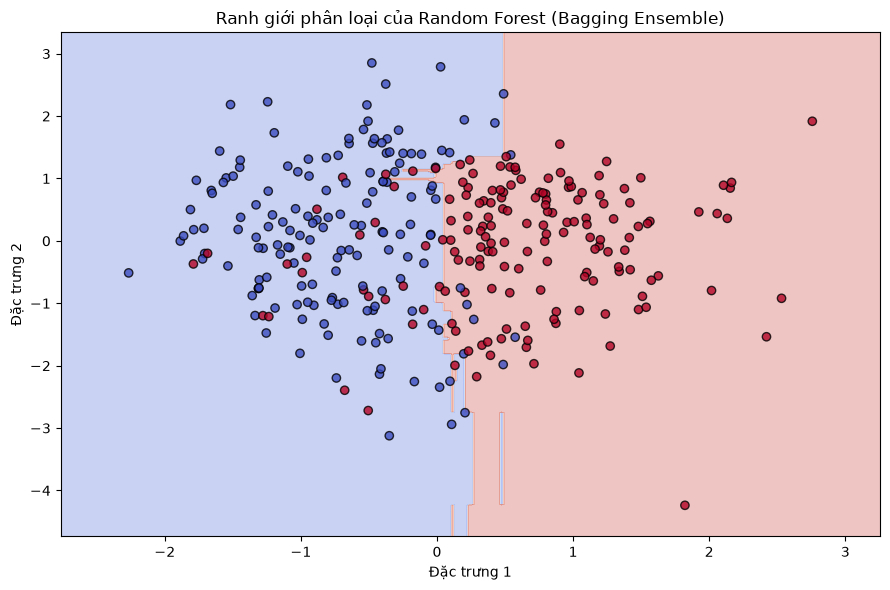

In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification
from utils.metrics import accuracy_score
from utils.preprocessing import train_test_split

# 1. Sinh dữ liệu (Tương tự Decision Tree nhưng làm nhiễu nhiều hơn một chút)
X, y = make_classification(n_samples=400, n_features=2, n_informative=2, 
                           n_redundant=0, n_classes=2, random_state=42, class_sep=0.7)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Huấn luyện model Scratch (Rừng 15 cây)
t0 = time.time()
model_scratch = RandomForestScratch(n_trees=15, max_depth=5).fit(X_train, y_train)
t_scratch = (time.time() - t0) * 1000

# 3. Huấn luyện model Sklearn
t0 = time.time()
model_sklearn = RandomForestClassifier(n_estimators=15, max_depth=5, random_state=42).fit(X_train, y_train)
t_sklearn = (time.time() - t0) * 1000

# 4. Đánh giá
y_pred_scratch = model_scratch.predict(X_test)
y_pred_sklearn = model_sklearn.predict(X_test)

print(f"{'Metric':<20} | {'Scratch':<15} | {'Sklearn':<15}")
print("-" * 55)
print(f"{'Accuracy Score':<20} | {accuracy_score(y_test, y_pred_scratch):<15.4f} | {accuracy_score(y_test, y_pred_sklearn):<15.4f}")
print(f"{'Time (ms)':<20} | {t_scratch:<15.2f} | {t_sklearn:<15.2f}")

# 5. Trực quan hóa ranh giới tổng hợp (Smoothed Boundaries)
plt.figure(figsize=(9, 6))

x_min, x_max = X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5
y_min, y_max = X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

Z = model_scratch.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', edgecolors='k', alpha=0.8)
plt.title("Ranh giới phân loại của Random Forest (Bagging Ensemble)")
plt.xlabel("Đặc trưng 1")
plt.ylabel("Đặc trưng 2")

plt.tight_layout()
plt.show()